> **A CHEM 438 final project from fall 2025**, shared as an example with the author's name removed. It used Our World in Data COVID table and World Bank GDP per capita. The data files are not included, so the cells will not rerun here: read it top to bottom, the figures and results are saved in the notebook.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy.optimize import curve_fit
from scipy.stats import linregress, ttest_1samp, ttest_ind
from scipy.stats import pearsonr
sns.set(style="white")

Will higher population density result in higher total COVID cases per million people? Will lower population density result in lower total COVID cases per million people?

Hypothesis: Higher population density will result in a higher number of COVID cases.

Loading the COVID dataset:

In [ ]:
df_covid = pd.read_csv('COVID dataset.csv')

In [ ]:
df_covid

,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,...,population,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand,human_development_index
0,Afghanistan,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN
1,Afghanistan,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN
2,Afghanistan,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN
3,Afghanistan,2020-01-04,0.0,0.0,NaN,0.000,0.0,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN
4,Afghanistan,2020-01-05,0.0,0.0,NaN,0.000,0.0,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
126939,Djibouti,2024-05-12,15690.0,0.0,0.0,13798.247,0.0,0.0,189.0,0.0,...,1137101.0,49.055264,24.084999,65.540199,4989.408691,25.36088,7.4,NaN,1.40,NaN
126940,Djibouti,2024-05-13,15690.0,0.0,0.0,13798.247,0.0,0.0,189.0,0.0,...,1137101.0,49.055264,24.084999,65.540199,4989.408691,25.36088,7.4,NaN,1.40,NaN
126941,Djibouti,2024-05-14,15690.0,0.0,0.0,13798.247,0.0,0.0,189.0,0.0,...,1137101.0,49.055264,24.084999,65.540199,4989.408691,25.36088,7.4,NaN,1.40,NaN
126942,Djibouti,2024-05-15,15690.0,0.0,0.0,13798.247,0.0,0.0,189.0,0.0,...,1137101.0,49.055264,24.084999,65.540199,4989.408691,25.36088,7.4,NaN,1.40,NaN


Filtering df_covid to include only data from 2020:

In [ ]:
df_covid['date'] = pd.to_datetime(df_covid['date'])

In [ ]:
df_2020 = df_covid[df_covid['date'].dt.year == 2020].copy().reset_index(drop=True)

In [ ]:
df_2020

,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,...,population,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand,human_development_index
0,Afghanistan,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN
1,Afghanistan,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN
2,Afghanistan,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN
3,Afghanistan,2020-01-04,0.0,0.0,NaN,0.0000,0.000000,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN
4,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0000,0.000000,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21916,Djibouti,2020-12-27,5805.0,1.0,3.428571,5105.0874,0.879429,3.015186,61.0,0.0,...,1137101.0,49.055264,24.084999,65.540199,4989.408691,25.36088,7.4,NaN,1.40,NaN
21917,Djibouti,2020-12-28,5813.0,8.0,4.571429,5112.1230,7.035435,4.020248,61.0,0.0,...,1137101.0,49.055264,24.084999,65.540199,4989.408691,25.36088,7.4,NaN,1.40,NaN
21918,Djibouti,2020-12-29,5813.0,0.0,4.285714,5112.1230,0.000000,3.768983,61.0,0.0,...,1137101.0,49.055264,24.084999,65.540199,4989.408691,25.36088,7.4,NaN,1.40,NaN
21919,Djibouti,2020-12-30,5813.0,0.0,3.857143,5112.1230,0.000000,3.392085,61.0,0.0,...,1137101.0,49.055264,24.084999,65.540199,4989.408691,25.36088,7.4,NaN,1.40,NaN


Creating a function to seperate countries into income categories:

In [ ]:
def gdp_group(gdp):
    if gdp < 5000:
        return "Low-income"
    elif gdp < 20000:
        return "Middle-income"
    else:
        return "High-income"

Adding a column with income groups:

In [ ]:
df_2020['income_group'] = df_2020['gdp_per_capita'].apply(gdp_group)

In [ ]:
df_2020

,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,...,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand,human_development_index,income_group
0,Afghanistan,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN,Low-income
1,Afghanistan,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN,Low-income
2,Afghanistan,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN,Low-income
3,Afghanistan,2020-01-04,0.0,0.0,NaN,0.0000,0.000000,NaN,0.0,0.0,...,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN,Low-income
4,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0000,0.000000,NaN,0.0,0.0,...,62.215549,16.752001,65.616997,1516.273315,NaN,10.9,48.214695,0.39,NaN,Low-income
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21916,Djibouti,2020-12-27,5805.0,1.0,3.428571,5105.0874,0.879429,3.015186,61.0,0.0,...,49.055264,24.084999,65.540199,4989.408691,25.36088,7.4,NaN,1.40,NaN,Low-income
21917,Djibouti,2020-12-28,5813.0,8.0,4.571429,5112.1230,7.035435,4.020248,61.0,0.0,...,49.055264,24.084999,65.540199,4989.408691,25.36088,7.4,NaN,1.40,NaN,Low-income
21918,Djibouti,2020-12-29,5813.0,0.0,4.285714,5112.1230,0.000000,3.768983,61.0,0.0,...,49.055264,24.084999,65.540199,4989.408691,25.36088,7.4,NaN,1.40,NaN,Low-income
21919,Djibouti,2020-12-30,5813.0,0.0,3.857143,5112.1230,0.000000,3.392085,61.0,0.0,...,49.055264,24.084999,65.540199,4989.408691,25.36088,7.4,NaN,1.40,NaN,Low-income


Creating a graph showing population density and new COVID cases:

In [ ]:
df_grouped_pop = df_2020.groupby('country').agg({'population_density': 'mean', 'total_cases_per_million': 'mean'}).reset_index()
df_grouped_pop = df_grouped_pop.dropna()

In [ ]:
df_grouped_pop

,country,population_density,total_cases_per_million
0,Afghanistan,62.215549,573.230031
1,Africa,48.355656,562.425300
2,Albania,103.197594,3518.539540
3,Algeria,19.094181,634.967529
4,American Samoa,241.824997,0.000000
5,Andorra,169.621277,23342.720788
6,Angola,28.583483,102.517216
7,Anguilla,157.800003,203.478884
8,Antigua and Barbuda,211.022720,668.960128
9,Argentina,16.592272,9495.321163


Creating a graph that compares population density (on a log scale for better visualization) with total COVID cases in 2020 across all included countries:

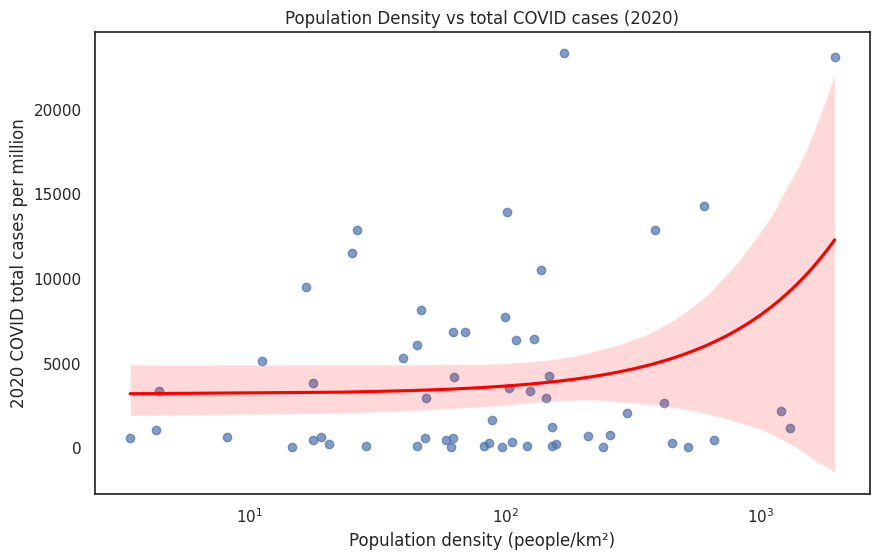

In [ ]:
plt.figure(figsize=(10,6))
sns.regplot(x='population_density', y='total_cases_per_million', data=df_grouped_pop,
scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
plt.xlabel('Population density (people/km²)')
plt.ylabel('2020 COVID total cases per million')
plt.title('Population Density vs total COVID cases (2020)')
plt.xscale('log')
plt.show()

In [ ]:
result = linregress(np.log10(df_grouped_pop['population_density']), df_grouped_pop['total_cases_per_million'])
print(f"R² = {result.rvalue**2:.4f}, p-value = {result.pvalue:.4f}")

R² = 0.0385, p-value = 0.1400


In low to medium population densities, there is little to no correlation between population density and the total number of COVID cases. We do see a sharp increase on the higher end of the scale, which is likely accounted for by ultra-densely populated countries. The R^2 value is incredibly low, and the p-value is not statistically significant, confirming this conclusion.

Maybe this result would be different in different income groups? Next, we will compare countries by income group to ensure the results are not concealed by other variables, like gdp.

In [ ]:
df_income = df_2020[['country', 'income_group']].copy()

In [ ]:
df_grouped_income = pd.merge(df_grouped_pop, df_income, on="country", how="inner")

In [ ]:
df_grouped_income

,country,population_density,total_cases_per_million,income_group
0,Afghanistan,62.215549,573.230031,Low-income
1,Afghanistan,62.215549,573.230031,Low-income
2,Afghanistan,62.215549,573.230031,Low-income
3,Afghanistan,62.215549,573.230031,Low-income
4,Afghanistan,62.215549,573.230031,Low-income
...,...,...,...,...
21187,Djibouti,49.055264,2896.416330,Low-income
21188,Djibouti,49.055264,2896.416330,Low-income
21189,Djibouti,49.055264,2896.416330,Low-income
21190,Djibouti,49.055264,2896.416330,Low-income


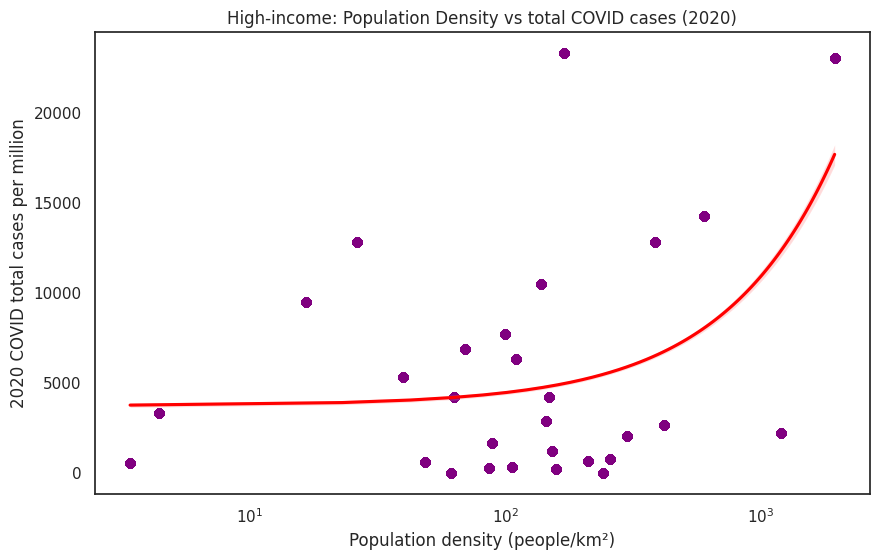

In [ ]:
plt.figure(figsize=(10,6))
sns.regplot(x='population_density', y='total_cases_per_million', data=df_grouped_income.query("income_group == 'High-income'"), color="purple",
scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
plt.xlabel('Population density (people/km²)')
plt.ylabel('2020 COVID total cases per million')
plt.title('High-income: Population Density vs total COVID cases (2020)')
plt.xscale('log')
plt.show()

In [ ]:
result = linregress(np.log10(df_grouped_income.query("income_group == 'High-income'")['population_density']), df_grouped_income.query("income_group == 'High-income'")['total_cases_per_million'])
print(f"R² = {result.rvalue**2:.4f}, p-value = {result.pvalue:.4f}")

R² = 0.0730, p-value = 0.0000


For the High-income countries, there is a very, very weak relationship here based on R^2 value, but the p-value is statistically significant.

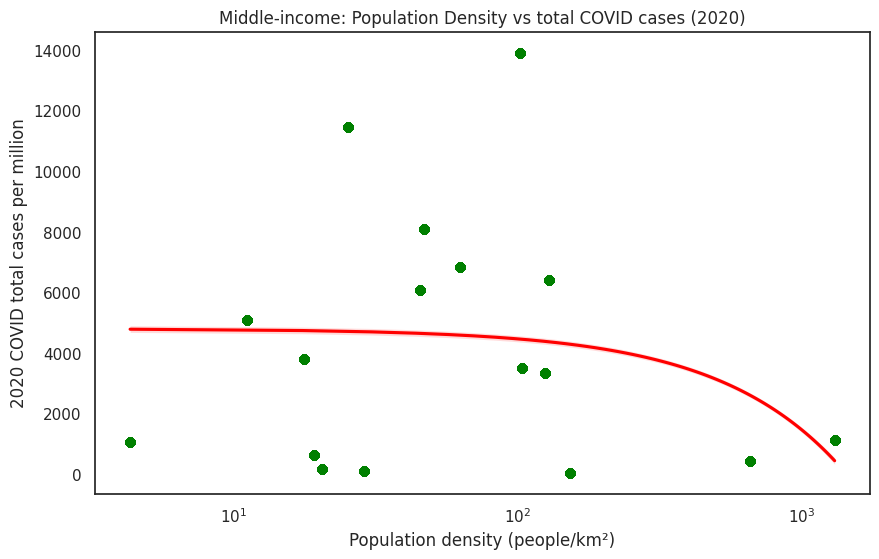

In [ ]:
plt.figure(figsize=(10,6))
sns.regplot(x='population_density', y='total_cases_per_million', data=df_grouped_income.query("income_group == 'Middle-income'"), color="green",
scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
plt.xlabel('Population density (people/km²)')
plt.ylabel('2020 COVID total cases per million')
plt.title('Middle-income: Population Density vs total COVID cases (2020)')
plt.xscale('log')
plt.show()

In [ ]:
result = linregress(np.log10(df_grouped_income.query("income_group == 'Middle-income'")['population_density']), df_grouped_income.query("income_group == 'Middle-income'")['total_cases_per_million'])
print(f"R² = {result.rvalue**2:.4f}, p-value = {result.pvalue:.4f}")

R² = 0.0034, p-value = 0.0000


Again, this variable explains nearly none of the trend, but the p-value is statistically significant.

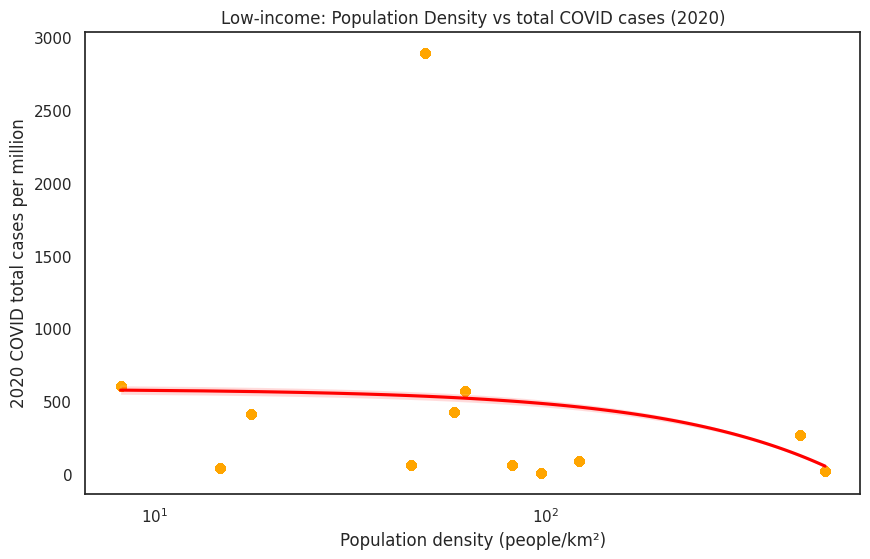

In [ ]:
plt.figure(figsize=(10,6))
sns.regplot(x='population_density', y='total_cases_per_million', data=df_grouped_income.query("income_group == 'Low-income'"), color="orange",
scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
plt.xlabel('Population density (people/km²)')
plt.ylabel('2020 COVID total cases per million')
plt.title('Low-income: Population Density vs total COVID cases (2020)')
plt.xscale('log')
plt.show()

In [ ]:
result = linregress(np.log10(df_grouped_income.query("income_group == 'Low-income'")['population_density']), df_grouped_income.query("income_group == 'Low-income'")['total_cases_per_million'])
print(f"R² = {result.rvalue**2:.4f}, p-value = {result.pvalue:.4f}")

R² = 0.0313, p-value = 0.0000


Again, a weak realationship with a statisically significant p-value.

The middle and low income datasets seem to reverse even the miniscule trend we saw before. Maybe this is due to a lack of data, since total COVID cases are hard to track in comparison to other variables, like vaccinations and deaths.

What if we looked at deaths instead of cases?

In [ ]:
df_grouped_deaths = df_2020.groupby('country').agg({'population_density': 'mean', 'total_deaths_per_million': 'mean'}).reset_index()
df_grouped_deaths = df_grouped_deaths.dropna()

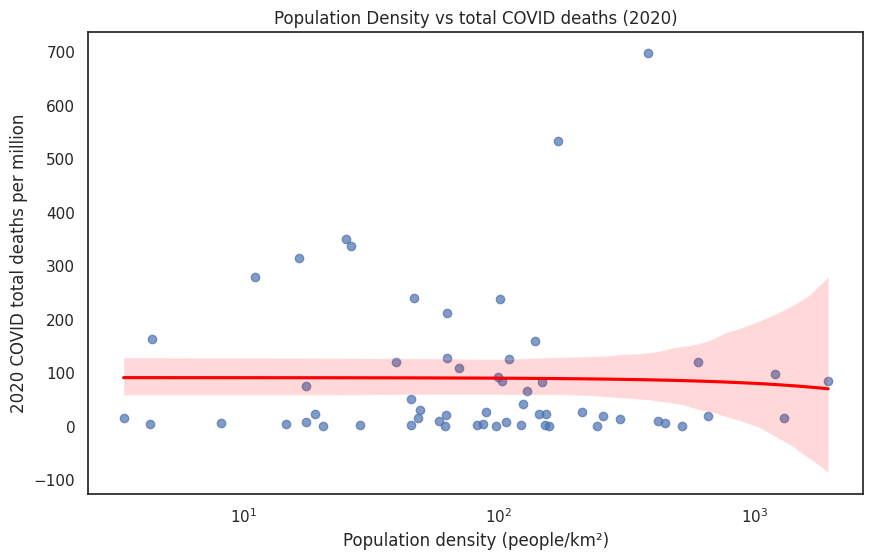

In [ ]:
plt.figure(figsize=(10,6))
sns.regplot(x='population_density', y='total_deaths_per_million', data=df_grouped_deaths,
scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
plt.xlabel('Population density (people/km²)')
plt.ylabel('2020 COVID total deaths per million')
plt.title('Population Density vs total COVID deaths (2020)')
plt.xscale('log')
plt.show()

In [ ]:
result = linregress(np.log10(df_grouped_deaths['population_density']), df_grouped_deaths['total_deaths_per_million'])
print(f"R² = {result.rvalue**2:.4f}, p-value = {result.pvalue:.4f}")

R² = 0.0004, p-value = 0.8832


Looking at deaths, which are easier to measure accurately than cases, we can see that there is nearly no coorelation between the variables, and the p-value is not statistically significant.

In [ ]:
df_grouped_deaths = pd.merge(df_grouped_deaths, df_income, on="country", how="inner")

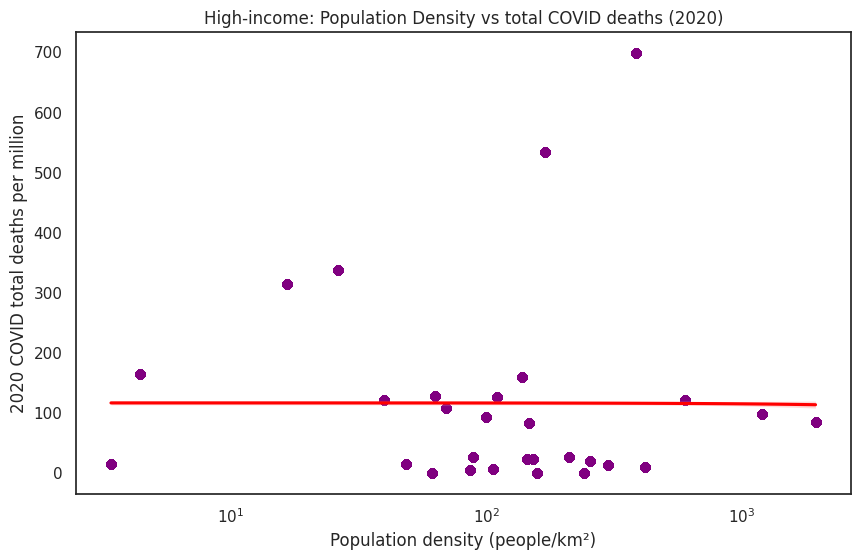

In [ ]:
plt.figure(figsize=(10,6))
sns.regplot(x='population_density', y='total_deaths_per_million', data=df_grouped_deaths.query("income_group == 'High-income'"), color="purple",
scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
plt.xlabel('Population density (people/km²)')
plt.ylabel('2020 COVID total deaths per million')
plt.title('High-income: Population Density vs total COVID deaths (2020)')
plt.xscale('log')
plt.show()

In [ ]:
result = linregress(np.log10(df_grouped_deaths.query("income_group == 'High-income'")['population_density']), df_grouped_deaths.query("income_group == 'High-income'")['total_deaths_per_million'])
print(f"R² = {result.rvalue**2:.4f}, p-value = {result.pvalue:.4f}")

R² = 0.0002, p-value = 0.1715


The high-income countries are consistent with the overall data conclusions, there is no correlation between the variables and the p-value is not statistically significant.

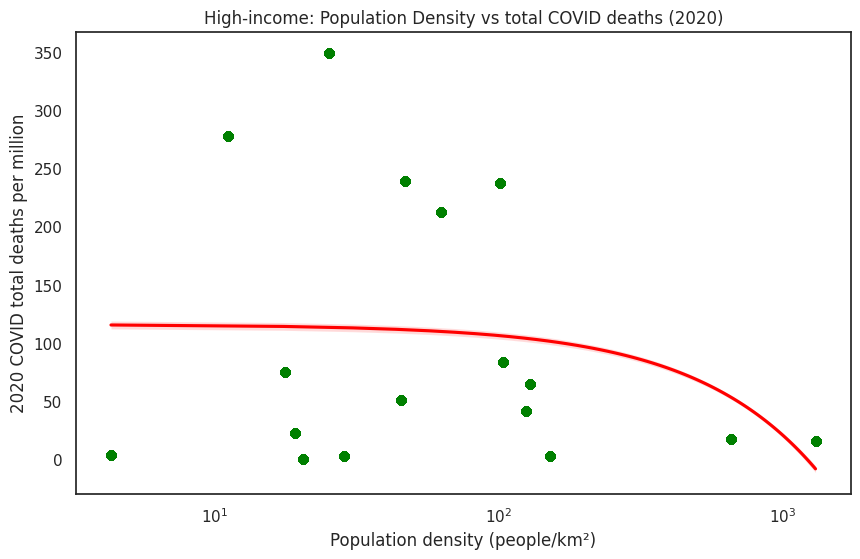

In [ ]:
plt.figure(figsize=(10,6))
sns.regplot(x='population_density', y='total_deaths_per_million', data=df_grouped_deaths.query("income_group == 'Middle-income'"), color="green",
scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
plt.xlabel('Population density (people/km²)')
plt.ylabel('2020 COVID total deaths per million')
plt.title('High-income: Population Density vs total COVID deaths (2020)')
plt.xscale('log')
plt.show()

In [ ]:
result = linregress(np.log10(df_grouped_deaths.query("income_group == 'Middle-income'")['population_density']), df_grouped_deaths.query("income_group == 'Middle-income'")['total_deaths_per_million'])
print(f"R² = {result.rvalue**2:.4f}, p-value = {result.pvalue:.4f}")

R² = 0.0411, p-value = 0.0000


The middle-income countries again find no corrrelation between the data, and a statistically significant p-value.

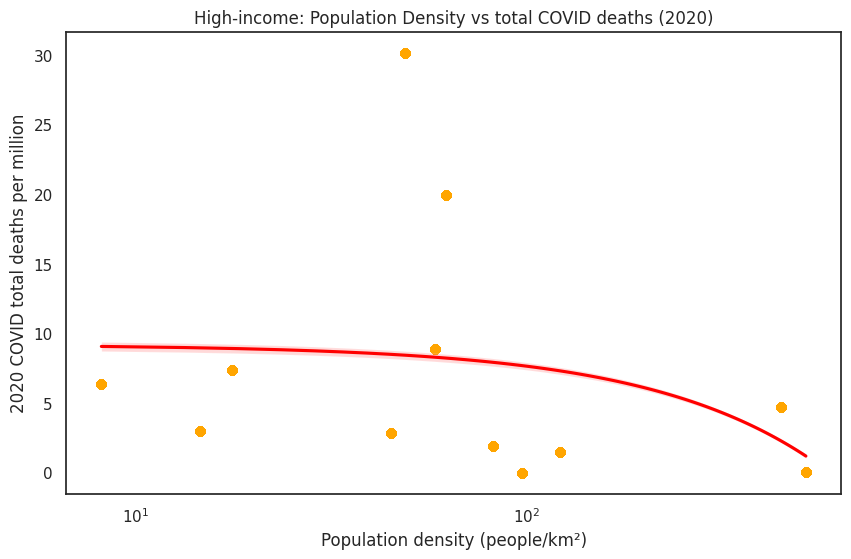

In [ ]:
plt.figure(figsize=(10,6))
sns.regplot(x='population_density', y='total_deaths_per_million', data=df_grouped_deaths.query("income_group == 'Low-income'"), color="orange",
scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
plt.xlabel('Population density (people/km²)')
plt.ylabel('2020 COVID total deaths per million')
plt.title('High-income: Population Density vs total COVID deaths (2020)')
plt.xscale('log')
plt.show()

In [ ]:
result = linregress(np.log10(df_grouped_deaths.query("income_group == 'Low-income'")['population_density']), df_grouped_deaths.query("income_group == 'Low-income'")['total_deaths_per_million'])
print(f"R² = {result.rvalue**2:.4f}, p-value = {result.pvalue:.4f}")

R² = 0.0408, p-value = 0.0000


The low-income countries again find no corrrelation between the data, and a statistically significant p-value.

The hypothesis is disproven, higher population density does not always lead to higher COVID cases, or more COVID deaths. There could be some differences in how population density impacts COVID depending on the income category of the country, even if in a minor way. There are likely other variables that have a larger impact on COVID outcomes, and these would be good research areas for future projects.